# 01 - Where is the sun in a KITTI frame?

Goal: get the sun direction in camera coordinates from OXTS (GPS + IMU) and the timestamp,
then check by eye that predicted shadow directions match the real shadows.

Open question we settle here: are KITTI timestamps local time (CEST, UTC+2) or UTC?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import kitti
import sun

DATE_DIR = ROOT / "data/raw/2011_09_26"
DRIVE = DATE_DIR / "2011_09_26_drive_0001_sync"
FIG = ROOT / "outputs/figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
oxts = kitti.read_oxts(DRIVE)
stamps = kitti.read_timestamps(DRIVE / "oxts/timestamps.txt")
calib = kitti.read_calib(DATE_DIR)
print("frames:", len(stamps), "| first stamp:", stamps[0])
print("lat/lon:", oxts["lat"][0], oxts["lon"][0])

frames: 108 | first stamp: 2011-09-26 13:02:25.964389
lat/lon: 49.015003823272 8.4342971002335


Sun position for both timezone guesses.

In [3]:
for off in (0, 2):
    s, az, el = sun.sun_in_camera(oxts, 0, stamps[0], calib, utc_offset_hours=off)
    print(f"UTC+{off}: azimuth {az:6.1f}  elevation {el:5.1f}  sun_cam {np.round(s, 3)}")

UTC+0: azimuth  212.5  elevation  34.9  sun_cam [-0.389 -0.561  0.731]
UTC+2: azimuth  175.0  elevation  39.7  sun_cam [-0.714 -0.617  0.332]


Draw where shadows *should* point. On flat ground, a shadow runs along the sun direction
projected onto the ground, pointing away from the sun. Camera y points down, so "up" is -y.

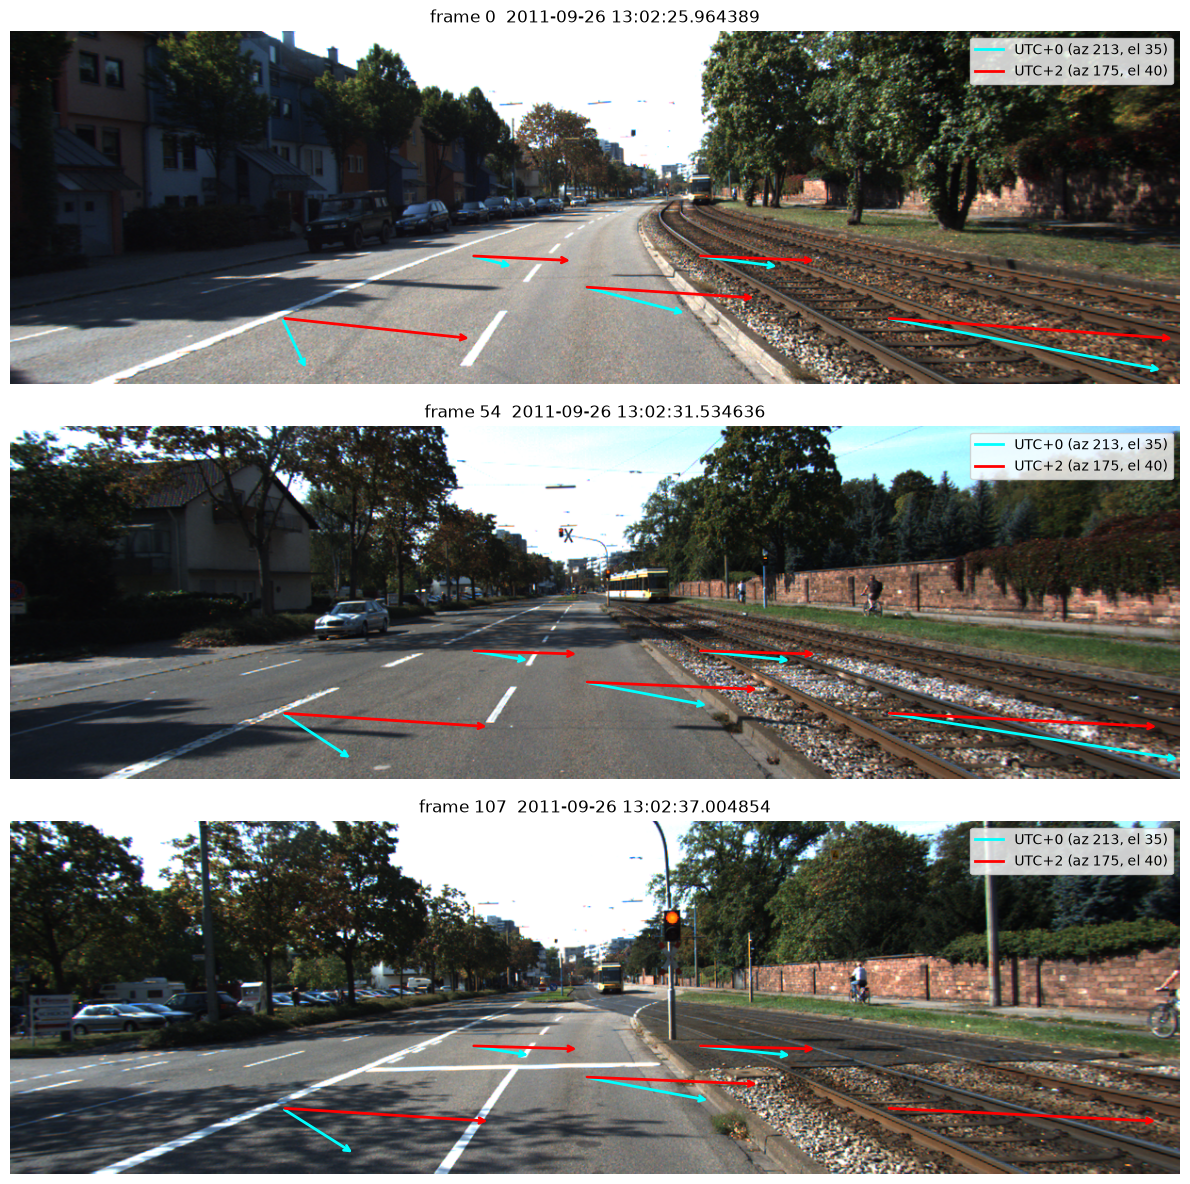

In [4]:
def shadow_arrows(ax, s_cam, K, color, label):
    up = np.array([0.0, -1.0, 0.0])
    d = -(s_cam - s_cam.dot(up) * up)
    d /= np.linalg.norm(d)
    cam_height = 1.65  # KITTI camera height above the road
    for x0, z0 in [(-4, 9), (0, 12), (4, 9), (-3, 18), (3, 18)]:
        a = np.array([x0, cam_height, z0])
        b = a + 3.0 * d
        pa, pb = K @ a, K @ b
        ax.annotate("", xy=pb[:2] / pb[2], xytext=pa[:2] / pa[2],
                    arrowprops=dict(arrowstyle="->", color=color, lw=2))
    ax.plot([], [], color=color, lw=2, label=label)


idx_list = [0, len(stamps) // 2, len(stamps) - 1]
fig, axes = plt.subplots(len(idx_list), 1, figsize=(12, 4 * len(idx_list)))
for ax, i in zip(axes, idx_list):
    img = kitti.load_image(DRIVE, i)
    ax.imshow(img)
    for off, col in [(0, "cyan"), (2, "red")]:
        s, az, el = sun.sun_in_camera(oxts, i, stamps[i], calib, off)
        shadow_arrows(ax, s, calib["K2"], col, f"UTC+{off} (az {az:.0f}, el {el:.0f})")
    ax.set_xlim(0, img.shape[1]); ax.set_ylim(img.shape[0], 0)
    ax.set_title(f"frame {i}  {stamps[i]}")
    ax.legend(loc="upper right")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "01_shadow_direction_check.png", dpi=80)
plt.show()